# Setup
First things first, we need to set up the notebook for our exercise today.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import os
from pathlib import Path

# Constants / Global Settings
SampleRate = 256  # Samples per second from the headset
plt.rcParams["figure.figsize"] = [30.00, 5.00]  # Makes the plots a little wider

# Point to the dataset root. Override with the EEG_DATA_ROOT environment variable if needed.
data_root = Path(os.getenv("EEG_DATA_ROOT", "NeuroTune/emotions_dataset"))
print(f"Using dataset root: {data_root.resolve()}")


Cloning into 'NeuroTune'...
remote: Enumerating objects: 36684, done.
remote: Counting objects: 100% (73/73), done.
remote: Compressing objects: 100% (34/34), done.
remote: Total 36684 (delta 56), reused 42 (delta 39), pack-reused 36611 (from 2)
Receiving objects: 100% (36684/36684), 1.18 GiB | 20.75 MiB/s, done.
Resolving deltas: 100% (6169/6169), done.
Updating files: 100% (1071/1071), done.


# Step 1:
Open and Format

In [2]:
channel = []
filename = "NeuroTune/emotions_dataset/Happy/Brainwaves_Happy_1.csv"



with open(filename, "r") as data:
    for line in data:
        line = line.split(",")
        channel.append(float(line[1]))

<details>
  <summary>Solution</summary>

  ```
  channel = []
  filename = "/content/eo.csv"

  with open(filename, "r") as data:
      for line in data:
          line = line.split(",")
          channel.append(float(line[1]))
  ```
</details>

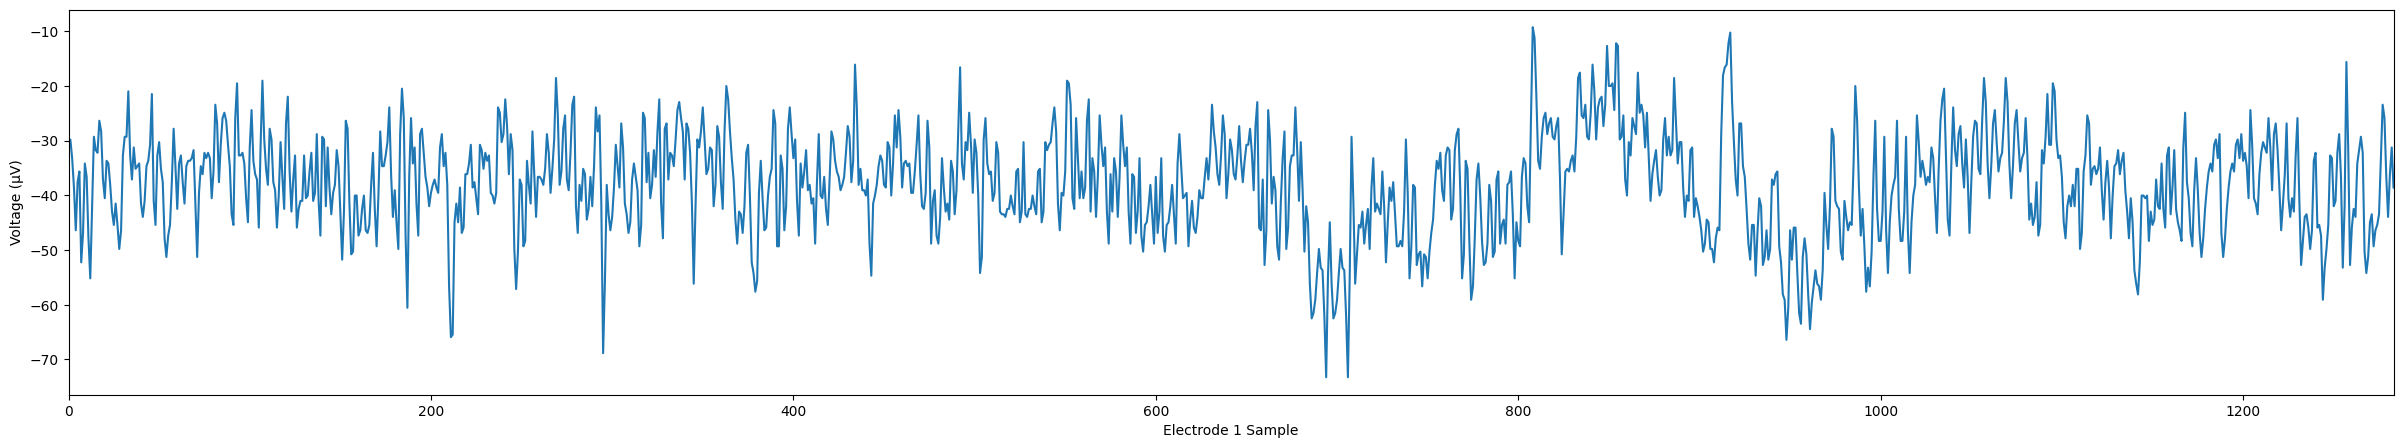

In [3]:
# Show a plot of the raw brainwave
time = np.arange(0, len(channel), 1)

plt.plot(time, channel)
plt.xlabel("Electrode 1 Sample")
plt.ylabel("Voltage (μV)")
plt.margins(x=0)
plt.show()

# Step 2:
Fast Fourier Transform

In [18]:
# Fourier transform
fftData = np.fft.fft(channel)
freq = np.fft.fftfreq(len(channel)) * SampleRate

# Now we just plot the transformed data (the exact same wave but in the frequency domain)
plotFreq    = freq[1:int(len(freq)/2)]                  # Remove negative reflection
plotFftData = fftData[1:int(len(fftData)/2)]            # Remove negative reflection
plotMag     = plotFftData.real**2 + plotFftData.imag**2 # FFT is a complex function, so we need to cast to the real domain

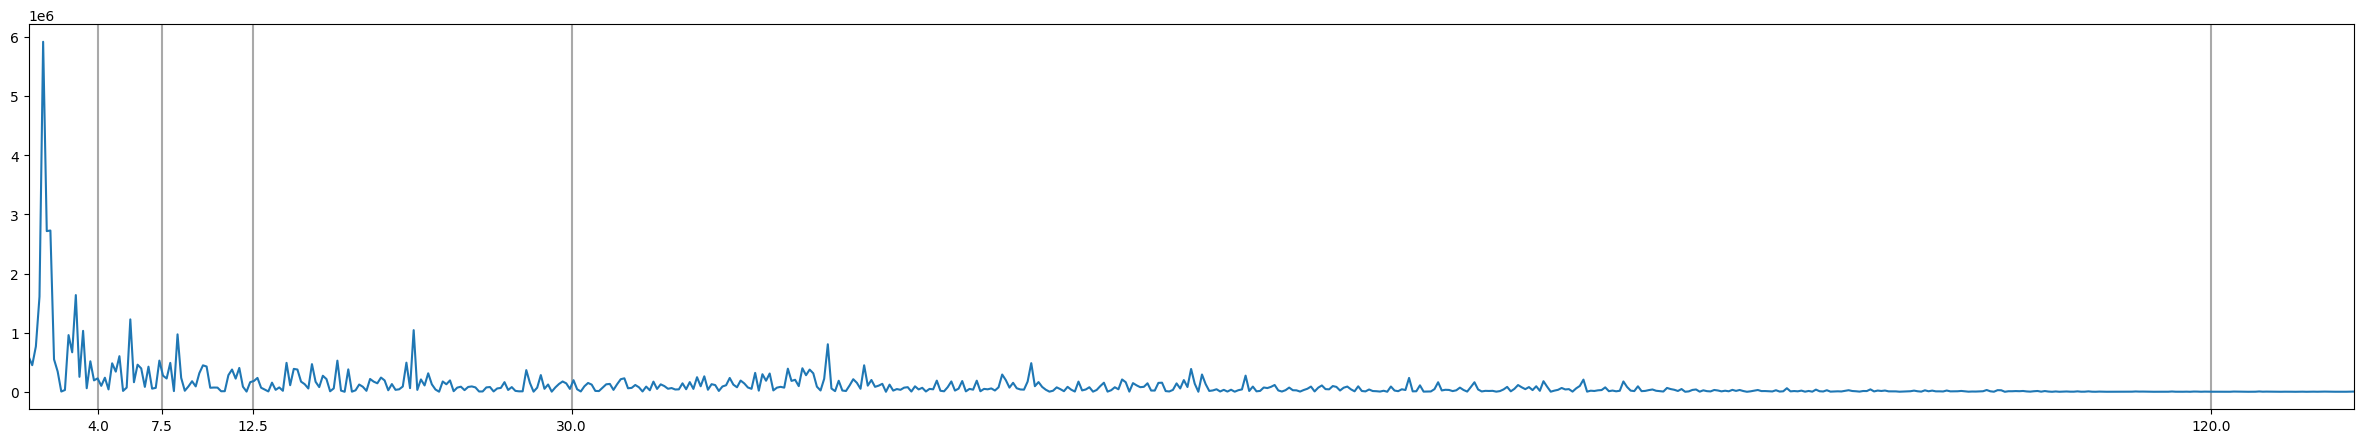

In [19]:
isShowingBinLines = True

# Create the plot
fig = plt.figure()
ax = fig.add_subplot()

# Add the special spacing
if(isShowingBinLines):
  subsets=[0, 4, 7.5, 12.5, 30, 120]
  ax.set_xticks(subsets)

# Add the vertical lines
if(isShowingBinLines):
  plt.axvline(x=4, color="darkgrey")
  plt.axvline(x=7.5, color="darkgrey")
  plt.axvline(x=12.5, color="darkgrey")
  plt.axvline(x=30, color="darkgrey")
  plt.axvline(x=120, color="darkgrey")

# Plot
ax.margins(x=0)
ax.plot(plotFreq, plotMag)
plt.show()

#Step 3:
Power Bins

In [20]:
# Bin the results
binsAverage = [0,0,0,0,0] # We will append to this later
binsTotal   = [0,0,0,0,0]
binsCount   = [0,0,0,0,0]

for point in range(len(plotFreq)):
  frequency = plotFreq[point]

  if(frequency < 4):      # Delta (0 - 4Hz)
    binsTotal[0] += plotMag[point]
    binsCount[0] += 1

  elif(frequency < 7.5):  # Theta (4 - 7.5Hz)
    binsTotal[1] += plotMag[point]
    binsCount[1] += 1

  elif(frequency < 12.5): # Alpha (7.5 - 12.5Hz)
    binsTotal[2] += plotMag[point]
    binsCount[2] += 1

  elif(frequency < 30):   # Beta  (12.5 - 30Hz)
    binsTotal[3] += plotMag[point]
    binsCount[3] += 1

  elif(frequency < 120):   # Gamma (30 - 120Hz)
    binsTotal[4] += plotMag[point]
    binsCount[4] += 1

# Compute the average for all of them
binsAverage = list(np.array(binsTotal)/np.array(binsCount))

print("Total:  ", binsTotal)
print("Count:  ", binsCount)
print("Average:", binsAverage)

Total:   [np.float64(21246761.86011827), np.float64(5280566.181029629), np.float64(5535572.270117752), np.float64(11817974.303478997), np.float64(26478545.891842265)]
Count:   [20, 17, 25, 88, 451]
Average: [np.float64(1062338.0930059135), np.float64(310621.5400605664), np.float64(221422.8908047101), np.float64(134295.16253953407), np.float64(58710.74477126888)]


#Step 3.5
Here we are going to move all of what we've written above into a function that we can use to easily run everything on our data later!

In [38]:
def getPowerBinsFromFilename(filename, debug=False):
  if(str(type(filename)) != "<class 'str'>"): # Error handling
    if debug: print("Error: filename must be a string.")
    return None

  ## Open the data ##
  channels = [[], [], [], []]  # 4 channels: columns 0, 1, 2, 3
  with open(filename, "r") as data:
    for line in data:
        line = line.split(",")
        # Read columns 0-3 (all 4 EEG channels)
        for ch in range(4):
            try:
                channels[ch].append(float(line[ch]))
            except (IndexError, ValueError):
                pass

  # Convert to numpy arrays
  channels = [np.array(ch, dtype=float) for ch in channels]

  if debug:
    print(f"Loaded channels: {[len(ch) for ch in channels]} samples each")

  # Skip files with insufficient data (need at least 16 samples for FFT + filter)
  min_length = 16
  if any(len(ch) < min_length for ch in channels):
    if debug: print(f"Skipping: channel too short (min={min_length})")
    return None

  # Apply low-pass filter to each channel (wrapped in try-except)
  try:
    from scipy import signal
    nyquist = SampleRate / 2
    cutoff = 30  # Hz
    b, a = signal.butter(3, cutoff / nyquist, btype='low')
    channels = [signal.filtfilt(b, a, ch) for ch in channels]
    if debug:
      print(f"Filter applied successfully, new lengths: {[len(ch) for ch in channels]}")
  except Exception as e:
    # If filter fails, return None
    if debug: print(f"Filter failed: {type(e).__name__}: {e}")
    return None

  # Compute bins for each channel separately, then average
  all_channel_bins = []

  for channel_idx, channel in enumerate(channels):
    # Double-check channel has data after filtering
    if len(channel) == 0:
      if debug: print(f"Channel {channel_idx} empty after filter")
      return None

    ## Fourier transform the data ##
    try:
      fftData = np.fft.fft(channel)
      freq = np.fft.fftfreq(len(channel)) * SampleRate

      outFftData = fftData[1:int(len(fftData)/2)]
      outMag     = outFftData.real**2 + outFftData.imag**2
      outFreq    = freq[1:int(len(freq)/2)]
    except Exception as e:
      if debug: print(f"FFT failed on channel {channel_idx}: {type(e).__name__}: {e}")
      return None

    ## Bin the data ##
    binsTotal   = [0,0,0,0,0]
    binsCount   = [0,0,0,0,0]

    for point in range(len(outFreq)):
      frequency = outFreq[point]

      if(frequency < 4):      # Delta (0 - 4Hz)
        binsTotal[0] += outMag[point]
        binsCount[0] += 1

      elif(frequency < 7.5):  # Theta (4 - 7.5Hz)
        binsTotal[1] += outMag[point]
        binsCount[1] += 1

      elif(frequency < 12.5): # Alpha (7.5 - 12.5Hz)
        binsTotal[2] += outMag[point]
        binsCount[2] += 1

      elif(frequency < 30):   # Beta  (12.5 - 30Hz)
        binsTotal[3] += outMag[point]
        binsCount[3] += 1

      elif(frequency < 120):   # Gamma (30 - 120Hz)
        binsTotal[4] += outMag[point]
        binsCount[4] += 1

    # Compute averages for this channel
    binsAverage = [total / count if count != 0 else 0 for total, count in zip(binsTotal, binsCount)]
    all_channel_bins.append(binsAverage)

    if debug and channel_idx == 0:
      print(f"Channel 0 bins: {binsAverage}")

  # Average across all 4 channels
  final_bins = np.mean(all_channel_bins, axis=0).tolist()

  if debug:
    print(f"Final averaged bins: {final_bins}")

  # Convert to RELATIVE power (normalize by total)
  total_power = sum(final_bins)
  if total_power > 0:
    final_bins = [b / total_power for b in final_bins]
  else:
    if debug: print("Total power is 0, returning None")
    return None

  if debug:
    print(f"Relative power bins: {final_bins}")

  # Finished computing the bins, return them
  return final_bins

# PREPROCESSING!!!!!!!!!!!!!!!!!!!!

In [39]:
# Debug a single CSV to see why it's skipped
import pathlib

def debug_csv(path):
    p = pathlib.Path(path)
    print(f"\n--- Debugging {p} ---")
    print(f"Exists: {p.exists()}  Size: {p.stat().st_size if p.exists() else 'N/A'} bytes")
    if not p.exists():
        return
    # Show first 3 raw lines
    with open(p, 'r') as f:
        raw_lines = [next(f).strip() for _ in range(3)]
    print("First 3 lines:")
    for ln in raw_lines:
        print(f"  {ln}")
    # Count rows quickly
    with open(p, 'r') as f:
        row_count = sum(1 for _ in f)
    print(f"Total rows: {row_count}")
    # Use pandas to inspect columns
    try:
        df_head = pd.read_csv(p, header=None, nrows=5)
        print(f"Pandas shape: {df_head.shape}")
        print(df_head)
    except Exception as e:
        print(f"pandas read_csv error: {e}")
    # Try the existing function WITH DEBUG
    print("\n=== Running getPowerBinsFromFilename with debug=True ===")
    bins = getPowerBinsFromFilename(str(p), debug=True)
    print(f"\n=== FINAL RESULT: {bins} ===")

# Example: inspect one file that should work
example_path = "NeuroTune/emotions_dataset/Sad/Brainwaves_Sad_1.csv"
debug_csv(example_path)


--- Debugging NeuroTune/emotions_dataset/Sad/Brainwaves_Sad_1.csv ---
Exists: True  Size: 58056 bytes
First 3 lines:
  -894.04296875,27.34375,-32.2265625,-901.3671875
  898.4375,16.11328125,-33.69140625,894.04296875
  987.3046875,8.30078125,-30.76171875,994.62890625
Total rows: 1284
Pandas shape: (5, 4)
            0          1          2           3
0 -894.042969  27.343750 -32.226562 -901.367188
1  898.437500  16.113281 -33.691406  894.042969
2  987.304688   8.300781 -30.761719  994.628906
3  908.691406   3.417969 -26.367188  907.714844
4 -979.980469  -1.953125 -27.832031 -974.609375

=== Running getPowerBinsFromFilename with debug=True ===
Loaded channels: [1284, 1284, 1284, 1284] samples each
Filter applied successfully, new lengths: [1284, 1284, 1284, 1284]
Channel 0 bins: [np.float64(11834034862.319115), np.float64(1112171415.1036818), np.float64(648009520.7916768), np.float64(1918638648.291004), np.float64(2329405.8852995387)]
Final averaged bins: [5941782353.552271, 534706865.

In [40]:
def wave_to_df(bins, mood):
    """Convert power bins to single-row dataframe with derived features"""
    if bins is None or len(bins) < 5:
        return pd.DataFrame(columns=["Delta", "Theta", "Alpha", "Beta", "Gamma", "Alpha_Theta_Ratio", "Beta_Alpha_Ratio", "LowFreq_HighFreq", "Mood"])

    delta, theta, alpha, beta, gamma = bins[:5]

    # Derived features with epsilon for numerical stability
    alpha_theta_ratio = alpha / (theta + 1e-8)
    beta_alpha_ratio = beta / (alpha + 1e-8)
    low_freq_high_freq = (delta + theta) / (beta + gamma + 1e-8)

    data = {
        'Delta': [delta],
        'Theta': [theta],
        'Alpha': [alpha],
        'Beta': [beta],
        'Gamma': [gamma],
        'Alpha_Theta_Ratio': [alpha_theta_ratio],
        'Beta_Alpha_Ratio': [beta_alpha_ratio],
        'LowFreq_HighFreq': [low_freq_high_freq],
        'Mood': [mood]
    }

    return pd.DataFrame(data)

def append_to_df(df, bins, mood):
    """Append power bins as new row to dataframe with derived features"""
    if bins is None or len(bins) < 5:
        return df

    delta, theta, alpha, beta, gamma = bins[:5]

    # Derived features with epsilon for numerical stability
    alpha_theta_ratio = alpha / (theta + 1e-8)
    beta_alpha_ratio = beta / (alpha + 1e-8)
    low_freq_high_freq = (delta + theta) / (beta + gamma + 1e-8)

    new_row = pd.DataFrame({
        'Delta': [delta],
        'Theta': [theta],
        'Alpha': [alpha],
        'Beta': [beta],
        'Gamma': [gamma],
        'Alpha_Theta_Ratio': [alpha_theta_ratio],
        'Beta_Alpha_Ratio': [beta_alpha_ratio],
        'LowFreq_HighFreq': [low_freq_high_freq],
        'Mood': [mood]
    })

    return pd.concat([df, new_row], ignore_index=True)

In [41]:
#processes each emotion folder in NeuroTune/emotions_old/...
def process_folder(folder_path, mood):

    #initialize df
    df = pd.DataFrame(columns=["Delta", "Theta", "Alpha", "Beta", "Gamma", "Alpha_Theta_Ratio", "Beta_Alpha_Ratio", "LowFreq_HighFreq", "Mood"])

    skipped = 0
    processed = 0

    for file_name in os.listdir(folder_path):
        if file_name.endswith(".csv"):
            file_path = os.path.join(folder_path, file_name)
            try:
                bins = getPowerBinsFromFilename(file_path)
                # Skip if file returned None (too short or error)
                if bins is None:
                    skipped += 1
                    continue

                if df.empty:
                    df = wave_to_df(bins, mood)
                else:
                    df = append_to_df(df, bins, mood)
                processed += 1
            except Exception as e:
                skipped += 1
                continue

    if skipped > 0:
        print(f"    (Skipped {skipped} files due to insufficient data or errors)")

    return df


#initialize dataframe
master_df = pd.DataFrame(columns=["Delta", "Theta", "Alpha", "Beta", "Gamma", "Alpha_Theta_Ratio", "Beta_Alpha_Ratio", "LowFreq_HighFreq", "Mood"])

# Process BOTH emotions_old AND emotions_dataset folders
dataset_folders = [
    ("NeuroTune/emotions_old", "emotions_old"),
    ("NeuroTune/emotions_dataset", "emotions_dataset")
]

for base_folder, folder_label in dataset_folders:
    print(f"\nProcessing {folder_label}...")

    for emotion in ["Happy", "Sad", "Angry", "Relaxed"]:
        folder_path = os.path.join(base_folder, emotion)

        # Check if folder exists before processing
        if os.path.exists(folder_path):
            print(f"  Processing {emotion} from {folder_label}...")
            folder_df = process_folder(folder_path, emotion)
            master_df = pd.concat([master_df, folder_df], ignore_index=True)
            print(f"    Added {len(folder_df)} samples")
        else:
            print(f"  Skipping {emotion} (folder not found)")

print(f"\n{'='*60}")
print(f"Total samples in master_df: {len(master_df)}")
print(f"Samples per emotion:")
print(master_df['Mood'].value_counts())
print(f"{'='*60}\n")
print("Features now include derived ratios for better separation:")
print("- Alpha_Theta_Ratio: Higher = more relaxed")
print("- Beta_Alpha_Ratio: Higher = more alert/stressed")
print("- LowFreq_HighFreq: Higher = more drowsy\n")
print(master_df.head())


Processing emotions_old...
  Processing Happy from emotions_old...
    Added 9 samples
  Processing Sad from emotions_old...


/tmp/ipython-input-2389614626.py:54: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  master_df = pd.concat([master_df, folder_df], ignore_index=True)


    Added 10 samples
  Processing Angry from emotions_old...
    Added 10 samples
  Processing Relaxed from emotions_old...
    Added 10 samples

Processing emotions_dataset...
  Processing Happy from emotions_dataset...
    Added 40 samples
  Processing Sad from emotions_dataset...
    Added 34 samples
  Processing Angry from emotions_dataset...
    Added 20 samples
  Processing Relaxed from emotions_dataset...
    Added 20 samples

Total samples in master_df: 153
Samples per emotion:
Mood
Happy      49
Sad        44
Angry      30
Relaxed    30
Name: count, dtype: int64

Features now include derived ratios for better separation:
- Alpha_Theta_Ratio: Higher = more relaxed
- Beta_Alpha_Ratio: Higher = more alert/stressed
- LowFreq_HighFreq: Higher = more drowsy

      Delta     Theta     Alpha      Beta     Gamma  Alpha_Theta_Ratio  \
0  0.355049  0.163278  0.220955  0.260347  0.000371           1.353241   
1  0.587100  0.078435  0.167747  0.166449  0.000270           2.138677   
2  0.3

# KAN!!!!!!!!!!!!!

In [42]:
# Dependencies are already available in the repo requirements. No runtime installs needed.


In [43]:
import numpy as np
import pandas as pd
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler

np.random.seed(42)
torch.manual_seed(42)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Training on device: {device}")


In [46]:
# Encode labels
label_encoder = LabelEncoder()
master_df['Mood'] = label_encoder.fit_transform(master_df['Mood'])

# DATA AUGMENTATION: Add slight noise to features to expand training data
# This helps with small datasets and improves generalization

def augment_data(X, y, noise_factor=0.03, augment_multiplier=3):
    """Add Gaussian noise to features to create augmented samples"""
    X_aug = [X]
    y_aug = [y]

    for _ in range(augment_multiplier):
        noise = np.random.normal(0, noise_factor, X.shape)
        X_aug.append(X + noise)
        y_aug.append(y)

    X_augmented = np.vstack(X_aug)
    y_augmented = np.hstack(y_aug)
    return X_augmented, y_augmented

# Use all 8 features (5 band powers + 3 derived ratios)
feature_cols = ['Delta', 'Theta', 'Alpha', 'Beta', 'Gamma', 'Alpha_Theta_Ratio', 'Beta_Alpha_Ratio', 'LowFreq_HighFreq']
X_raw = master_df[feature_cols].values
y_raw = master_df['Mood'].values

print(f"Original dataset size: {len(X_raw)} samples")
print(f"Features: {feature_cols}")

# Apply augmentation to expand dataset
X_raw, y_raw = augment_data(X_raw, y_raw, noise_factor=0.025, augment_multiplier=4)
print(f"After augmentation: {len(X_raw)} samples")

# Stratified split to preserve class balance
X_train_raw, X_test_raw, y_train_np, y_test_np = train_test_split(
    X_raw, y_raw, test_size=0.2, random_state=42, stratify=y_raw
)

# Fit scaler ONLY on train (avoid data leakage)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_raw)
X_test_scaled = scaler.transform(X_test_raw)

# Convert to tensors
X_train = torch.tensor(X_train_scaled, dtype=torch.float32)
y_train = torch.tensor(y_train_np, dtype=torch.long)
X_test = torch.tensor(X_test_scaled, dtype=torch.float32)
y_test = torch.tensor(y_test_np, dtype=torch.long)

# Class weights to mitigate imbalance: weight_i ∝ N / n_i
class_counts = np.bincount(y_train_np, minlength=len(label_encoder.classes_))
N = class_counts.sum()
class_weights = (N / (class_counts + 1e-8)).astype(np.float32)
class_weights = class_weights / class_weights.sum() * len(class_weights)  # normalize around 1.0
loss_weights_tensor = torch.tensor(class_weights, dtype=torch.float32).to(device)

train_ds = TensorDataset(X_train, y_train)
test_ds = TensorDataset(X_test, y_test)
train_loader = DataLoader(train_ds, batch_size=64, shuffle=True)
test_loader = DataLoader(test_ds, batch_size=64, shuffle=False)

print('Class counts:', class_counts)
print('Class weights:', class_weights)


Original dataset size: 153 samples
Features: ['Delta', 'Theta', 'Alpha', 'Beta', 'Gamma', 'Alpha_Theta_Ratio', 'Beta_Alpha_Ratio', 'LowFreq_HighFreq']
After augmentation: 459 samples
checkpoint directory created: ./model
saving model version 0.0
Class counts: [ 72 117  72 106]
Class weights: [1.2140969  0.74713653 1.2140969  0.8246696 ]
Model architecture: [[8, 0], [8, 0], [4, 0]]


In [ ]:
# A lightweight feedforward network that works well on small tabular datasets
class EmotionNet(nn.Module):
    def __init__(self, input_dim=8, num_classes=4, hidden=64, dropout=0.25):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(input_dim, hidden),
            nn.BatchNorm1d(hidden),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(hidden, hidden // 2),
            nn.BatchNorm1d(hidden // 2),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(hidden // 2, num_classes)
        )

    def forward(self, x):
        return self.net(x)


def accuracy_from_logits(logits, labels):
    preds = torch.argmax(logits, dim=1)
    return (preds == labels).float().mean().item()


def evaluate(model, loader, loss_fn):
    model.eval()
    total_loss = 0.0
    total_acc = 0.0
    count = 0
    with torch.no_grad():
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            logits = model(xb)
            loss = loss_fn(logits, yb)
            total_loss += loss.item() * len(xb)
            total_acc += accuracy_from_logits(logits, yb) * len(xb)
            count += len(xb)
    return total_loss / count, total_acc / count


model = EmotionNet(input_dim=X_train.shape[1], num_classes=len(label_encoder.classes_)).to(device)
loss_fn = nn.CrossEntropyLoss(weight=loss_weights_tensor)
optimizer = torch.optim.Adam(model.parameters(), lr=0.001, weight_decay=1e-3)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='max', patience=8, factor=0.5, verbose=True)


In [ ]:
# Train with early stopping based on validation (test) accuracy
best_state = None
best_acc = 0.0
patience = 12
tolerance = patience
num_epochs = 120
train_history, test_history = [], []

for epoch in range(1, num_epochs + 1):
    model.train()
    epoch_loss = 0.0
    for xb, yb in train_loader:
        xb, yb = xb.to(device), yb.to(device)
        optimizer.zero_grad()
        logits = model(xb)
        loss = loss_fn(logits, yb)
        loss.backward()
        optimizer.step()
        epoch_loss += loss.item() * len(xb)

    train_loss, train_acc = evaluate(model, train_loader, loss_fn)
    test_loss, test_acc = evaluate(model, test_loader, loss_fn)
    train_history.append(train_acc)
    test_history.append(test_acc)
    scheduler.step(test_acc)

    if test_acc > best_acc + 1e-4:
        best_acc = test_acc
        best_state = model.state_dict()
        tolerance = patience
    else:
        tolerance -= 1

    if epoch % 10 == 0 or tolerance == patience:
        print(f"Epoch {epoch:03d} | Train Acc: {train_acc:.3f} | Test Acc: {test_acc:.3f} | LR: {optimizer.param_groups[0]['lr']:.5f}")

    if tolerance == 0:
        print("Early stopping triggered")
        break

# Restore best model
if best_state is not None:
    model.load_state_dict(best_state)

print(f"\nBest validation accuracy: {best_acc:.3f}")


In [ ]:
# Print predictions as emotion strings

def print_predictions(data_input, data_label, label_encoder, dataset_type):
    model.eval()
    with torch.no_grad():
        predictions = torch.argmax(model(data_input.to(device)), dim=1).cpu().numpy()
    actual_labels = data_label.numpy()

    # Decode numeric predictions and actual labels to strings
    decoded_predictions = label_encoder.inverse_transform(predictions)
    decoded_actual = label_encoder.inverse_transform(actual_labels)

    print(f"
{dataset_type} Predictions:")
    for i in range(len(decoded_predictions)):
        print(f"Predicted: {decoded_predictions[i]}, Actual: {decoded_actual[i]}")


In [ ]:
# Detailed confusion matrix analysis
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns

# Get predictions
train_preds = torch.argmax(model(dataset['train_input']), dim=1).numpy()
test_preds = torch.argmax(model(dataset['test_input']), dim=1).numpy()
train_actual = dataset['train_label'].numpy()
test_actual = dataset['test_label'].numpy()

# Confusion matrix for TEST set (most important)
cm_test = confusion_matrix(test_actual, test_preds)
emotion_names = label_encoder.classes_

print("="*60)
print("TEST SET CONFUSION MATRIX")
print("="*60)
print("\nRows = Actual, Columns = Predicted\n")
print(f"{'':10}", end="")
for name in emotion_names:
    print(f"{name:10}", end="")
print()
for i, name in enumerate(emotion_names):
    print(f"{name:10}", end="")
    for j in range(len(emotion_names)):
        print(f"{cm_test[i,j]:10}", end="")
    print()

# Per-class accuracy
print("\n" + "="*60)
print("PER-CLASS ACCURACY (Test Set)")
print("="*60)
for i, emotion in enumerate(emotion_names):
    class_correct = cm_test[i, i]
    class_total = cm_test[i, :].sum()
    class_acc = class_correct / class_total if class_total > 0 else 0
    print(f"{emotion:10}: {class_acc:6.2%} ({class_correct}/{class_total})")

# Classification report
print("\n" + "="*60)
print("DETAILED CLASSIFICATION REPORT")
print("="*60)
print(classification_report(test_actual, test_preds, target_names=emotion_names, zero_division=0))

# Check if model is just predicting one class
unique_preds, counts = np.unique(test_preds, return_counts=True)
print("\n" + "="*60)
print("PREDICTION DISTRIBUTION (Test Set)")
print("="*60)
for pred_class, count in zip(unique_preds, counts):
    print(f"{label_encoder.inverse_transform([pred_class])[0]:10}: {count} predictions ({count/len(test_preds)*100:.1f}%)")


Train Predictions:
Predicted: 0, Actual: 0
Predicted: 3, Actual: 3
Predicted: 3, Actual: 3
Predicted: 1, Actual: 1
Predicted: 3, Actual: 3
Predicted: 3, Actual: 3
Predicted: 0, Actual: 0
Predicted: 3, Actual: 3
Predicted: 2, Actual: 2
Predicted: 1, Actual: 1
Predicted: 0, Actual: 0
Predicted: 1, Actual: 1
Predicted: 3, Actual: 3
Predicted: 1, Actual: 1
Predicted: 2, Actual: 2
Predicted: 0, Actual: 0
Predicted: 1, Actual: 1
Predicted: 2, Actual: 2
Predicted: 2, Actual: 2
Predicted: 1, Actual: 1
Predicted: 2, Actual: 2
Predicted: 0, Actual: 0
Predicted: 2, Actual: 2
Predicted: 3, Actual: 3
Predicted: 0, Actual: 0
Predicted: 3, Actual: 3
Predicted: 0, Actual: 0
Predicted: 1, Actual: 1
Predicted: 3, Actual: 3
Predicted: 0, Actual: 0
Predicted: 2, Actual: 2

Test Predictions:
Predicted: 2, Actual: 2
Predicted: 2, Actual: 2
Predicted: 0, Actual: 1
Predicted: 3, Actual: 3
Predicted: 2, Actual: 2
Predicted: 0, Actual: 0
Predicted: 1, Actual: 1
Predicted: 0, Actual: 0


# Diagnosis & Analysis

Run this cell to understand what's actually going wrong with predictions.

In [ ]:
# Assuming the necessary libraries (e.g., torch, scaler, label_encoder, etc.) are already imported

import warnings
warnings.filterwarnings("ignore", category=UserWarning)

new_instance = 'NeuroTune/emotions_dataset/Happy/Brainwaves_Happy_1.csv'

# Process the new instance to get bins
bin_avg = getPowerBinsFromFilename(new_instance)
print("Bin Averages:", bin_avg)

# Convert to tensor and add a batch dimension
bin_avg_scaled = scaler.transform([bin_avg])  # Transform expects 2D input
new_instance_tensor = torch.tensor(bin_avg_scaled, dtype=torch.float32).to(device)

# Pass the scaled instance through the model
logits = model(new_instance_tensor)

# Get the predicted class index
predicted_class_idx = torch.argmax(logits, dim=1).item()

# Decode the predicted index back to the emotion label
predicted_emotion = label_encoder.inverse_transform([predicted_class_idx])[0]

# Ensure that predicted_emotion is a string representing the class label
# Mapping index to emotion directly, since inverse_transform() will return string labels
print("Predicted Emotion: ", predicted_emotion)


Bin Averages: [np.float64(1062338.0930059135), np.float64(310621.5400605664), np.float64(221422.8908047101), np.float64(134295.16253953407), np.float64(58710.74477126888)]
Predicted Emotion:  1


saving model version 0.3


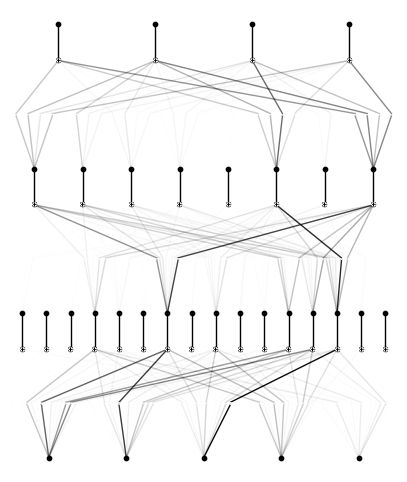

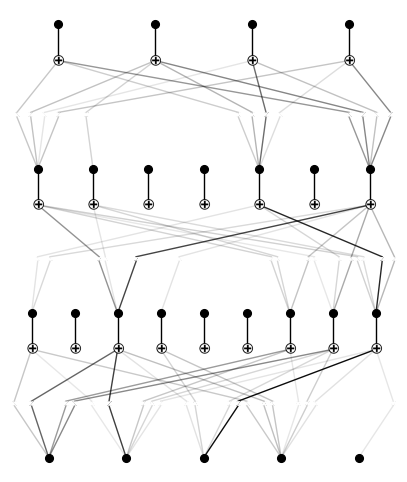

In [ ]:
# Plot training vs validation accuracy to verify stability
import matplotlib.pyplot as plt
plt.figure(figsize=(10,4))
plt.plot(train_history, label='Train accuracy')
plt.plot(test_history, label='Validation accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.title('EmotionNet training curve')
plt.legend()
plt.grid(True)
plt.show()


In [ ]:
# The KAN symbolic analysis step was removed; the new EmotionNet focuses on accuracy and stability.


--------------------------------------------------
fixing (0,0,0) with sin, r2=1.0000004768371582, c=2
fixing (0,0,1) with 0
fixing (0,0,2) with sin, r2=1.0000004768371582, c=2
fixing (0,0,3) with 0
fixing (0,0,4) with 0
fixing (0,0,5) with 0
fixing (0,0,6) with sin, r2=1.000000238418579, c=2
fixing (0,0,7) with sin, r2=0.9999998807907104, c=2
fixing (0,0,8) with 0
fixing (0,1,0) with sin, r2=0.9999169707298279, c=2
fixing (0,1,1) with 0
fixing (0,1,2) with sin, r2=0.9999945759773254, c=2
fixing (0,1,3) with 0
fixing (0,1,4) with 0
fixing (0,1,5) with 0
fixing (0,1,6) with sin, r2=0.9998970627784729, c=2
fixing (0,1,7) with sin, r2=0.992813766002655, c=2
fixing (0,1,8) with sin, r2=0.9999243021011353, c=2
fixing (0,2,0) with 0
fixing (0,2,1) with 0
fixing (0,2,2) with x^2, r2=0.9999841451644897, c=2
fixing (0,2,3) with sin, r2=0.997002899646759, c=2
fixing (0,2,4) with 0
fixing (0,2,5) with 0
fixing (0,2,6) with 0
fixing (0,2,7) with sin, r2=0.999976634979248, c=2
fixing (0,2,8) with s

In [ ]:
# Workspace check cell removed (no external shell commands required).


figures		   model	   NeuroTune	scaler.pkl
label_encoder.pkl  mood_model.pth  sample_data


In [ ]:
import torch
import pickle
import os
import shutil

# Paths
backend_models_dir = os.path.join('backend', 'models')
os.makedirs(backend_models_dir, exist_ok=True)

# Save locally first
model.cpu()  # ensure portability
torch.save(model.state_dict(), 'mood_model.pth')
with open('scaler.pkl', 'wb') as f:
    pickle.dump(scaler, f)
with open('label_encoder.pkl', 'wb') as f:
    pickle.dump(label_encoder, f)

print("
✓ Files saved in current directory:")
for f in ['mood_model.pth', 'scaler.pkl', 'label_encoder.pkl']:
    if os.path.exists(f):
        print(f"  ✓ {f} ({os.path.getsize(f)} bytes)")

# Copy to backend/models for inference
for f in ['mood_model.pth', 'scaler.pkl', 'label_encoder.pkl']:
    src = f
    dst = os.path.join(backend_models_dir, f)
    shutil.copyfile(src, dst)
    print(f"  → Copied {src} → {dst}")

print("
All artifacts are available at: backend/models/")


Notebook directory: /content
Current working directory: /content

✓ Files saved in kernel directory

Files in /content:
  ✓ mood_model.pth (17653 bytes)
  ✓ scaler.pkl (570 bytes)
  ✓ label_encoder.pkl (274 bytes)
